In [73]:
# import os

# data_path = "/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_1/fhir"
# files = os.listdir(data_path)  # List files in the directory
# print(files)


In [75]:
import pandas as pd
codes_in_synthea = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/codes_in_synthea.csv") #This might contain metadata or lookup tables for Synthea data (e.g., medical codes, demographic mappings, or diagnosis descriptions).
codes_in_synthea

,Description,count
0,Suicide - firearms,2
1,Attempted suicide - cut/stab,12
2,Attempted suicide - suffocation,12
3,History of upper limb amputation (situation),22
4,History of disarticulation at wrist (situation),24
...,...,...
175,Body Mass Index,6214829
176,Body Height,7041284
177,Diastolic Blood Pressure,7041284
178,Systolic Blood Pressure,7041284


# Output_2 file

I'm gonna use output_2 (there are data on 12,327 patients that i'm gonna use (found in all files))

In [1]:
import pandas as pd
import os

# Path to the dataset
data_path = r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_9/csv/"


In [2]:

# List of relevant files
files = [
    "allergies.csv", "careplans.csv", "conditions.csv", "encounters.csv",
    "immunizations.csv", "medications.csv", "observations.csv", "patients.csv",
    "procedures.csv"
]

# Initialize common_patients with the first file
first_file = os.path.join(data_path, files[0])
df = pd.read_csv(first_file, usecols=["PATIENT"])
common_patients = set(df["PATIENT"].unique())

# Iterate over remaining files and find the intersection
for file in files[1:]:
    print(file)
    file_path = os.path.join(data_path, file)
    if file=="patients.csv":
        df = pd.read_csv(f"{data_path}{file}", usecols=["ID"])  # Load only the 'PATIENT' column
        patient_ids = set(df["ID"].unique())
        continue
    df = pd.read_csv(file_path, usecols=["PATIENT"])
    patient_ids = set(df["PATIENT"].unique())
    
    # Find common patients
    common_patients &= patient_ids

# Convert to sorted list
common_patients = sorted(common_patients)

print(f"Found {len(common_patients)} common patients.")


careplans.csv
conditions.csv
encounters.csv
immunizations.csv
medications.csv
observations.csv
patients.csv
procedures.csv
Found 12025 common patients.


define the label that you want based on the conditions csv. i may take "Viral sinusitis (disorder)" 

In [51]:
# Read conditions.csv and filter for Viral_sinusitis
conditions_df = pd.read_csv(os.path.join(data_path, "conditions.csv"))
conditions_df = conditions_df[conditions_df["PATIENT"].isin(common_patients)]


In [52]:
condition_counts = conditions_df['DESCRIPTION'].value_counts()
condition_counts


Viral sinusitis (disorder)                                               8755
Acute viral pharyngitis (disorder)                                       4971
Acute bronchitis (disorder)                                              4401
Atopic dermatitis                                                        2688
Hypertension                                                             2601
                                                                         ... 
Lupus erythematosus                                                         3
Suicidal deliberate poisoning                                               1
Primary small cell malignant neoplasm of lung  TNM stage 3 (disorder)       1
Primary small cell malignant neoplasm of lung  TNM stage 2 (disorder)       1
History of lower limb amputation (situation)                                1
Name: DESCRIPTION, Length: 120, dtype: int64

In [48]:
2753/12323 #1

0.22340339203116125

In [41]:
2705/12327 #2

0.21943700819339662

In [53]:
2688/12025 #9

0.22353430353430354

In [65]:
labels_df['label'].sum()

2702

In [65]:
conditions_df[conditions_df['DESCRIPTION']=='Atopic dermatitis']

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION
39,1980-03-30,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,24079001,Atopic dermatitis
55,2015-07-12,NaN,79dbd8ca-79e1-47c4-b5ca-f1b5da7c83d1,724ed2d9-d372-4223-8a4e-33097462b640,24079001,Atopic dermatitis
321,2013-09-06,NaN,e97faa8d-b1b1-4a21-937a-86e6d6161b30,be73581c-2bd8-4813-9885-b97c1dbfeeee,24079001,Atopic dermatitis
1505,1948-03-23,NaN,371079fc-1567-4484-b8e3-e8fd26e97641,c8ed127e-ced8-4223-a6be-b952bd937291,24079001,Atopic dermatitis
1514,1984-08-19,NaN,ed599d26-b78a-4d6b-8c74-224fa07fcc6e,11f1f67f-689a-4b94-b706-9f3abd7a1c23,24079001,Atopic dermatitis
...,...,...,...,...,...,...
485287,1990-07-02,NaN,69510477-c1d7-49e9-8d02-1e875e8946a4,c623ce52-cc49-4894-8eb1-589ad7072df3,24079001,Atopic dermatitis
485323,1989-06-03,NaN,fed741e4-f6c7-4c05-93e5-3fa892233152,6723c22b-3f5f-4ab7-a06a-7d7f1179a946,24079001,Atopic dermatitis
485380,1998-10-18,NaN,99b82c48-0955-421a-aedf-a0c9fcb94c27,5bad4442-9d7f-4f30-a8c7-018671a3059a,24079001,Atopic dermatitis
485457,1993-01-02,NaN,ac12823a-6761-4df5-af06-17fd0d6f9638,194c83b9-0a13-4bfe-aeee-e45ae394e409,24079001,Atopic dermatitis


In [63]:
len(common_patients)

12327

In [36]:

# Identify patients with Atopic Dermatitis
ad_patients = set(conditions_df[conditions_df["CODE"]==24079001]["PATIENT"].unique())

# Assign labels
labels = {pid: 1 if pid in ad_patients else 0 for pid in common_patients} #2705



In [ ]:
# #convert and save it as dataframe
# labels_df = pd.DataFrame({'patient_id':labels.keys(),'label':labels.values()}) # len = n
# labels_df.to_csv('labels_Viral_sinusitis_synthea.csv')

In [ ]:
# #save the labels
# import json
# with open("labels_Viral_sinusitis.json", "w") as f:
#     json.dump(labels, f, indent=4)  # `indent=4` makes it more readable
# #read the saved labels json file
# with open("labels_Viral_sinusitis.json", "r") as f:
#     labels = json.load(f)

# print(labels)

create features for allergies.csv

In [72]:
def create_feature_EHR(relevant_features,df,time_col_name='START',target_col='DESCRIPTION') :   
    # List to store the allergy feature data
    data = []

    # Loop through the common patients and check if they have any of the relevant allergies
    for patient in common_patients:
        for feature in relevant_features:
            # Filter the allergies data for the patient
            patient_data = df[df['PATIENT'] == patient]
            
            # Check if the patient has the allergy
            has_feature = 1 if any(patient_data[target_col] == feature) else 0
            
            # Get the 'START' column as time
            if has_feature == 1:
                time_start = patient_data[patient_data[target_col] == feature][time_col_name].min()
            else:
                time_start = None  # If no allergy, no start time

            # Add the allergy feature to the list
            data.append({
                'patient_id': patient,
                'time': time_start,
                'feature_name': feature,
                'value': has_feature
            })

    # Convert the list into a DataFrame
    features_df = pd.DataFrame(data)

    # Ensure that the DataFrame has the right format (repeated patient_id for each allergy)
    # Repeat for all patients and allergies
    features_df = features_df.dropna(subset=["time"])  # drop rows without valid time

    # Sort by patient_id and time
    features_df.sort_values(by=["patient_id", "time"], inplace=True)

    return features_df

In [70]:
csv_allergies['DESCRIPTION'].unique()

array(['Shellfish allergy', 'Allergy to tree pollen',
       'Allergy to grass pollen', 'Dander (animal) allergy',
       'House dust mite allergy', 'Allergy to mould', 'Allergy to nut',
       'Allergy to fish', 'Allergy to wheat', 'Allergy to bee venom',
       'Allergy to peanuts', 'Allergy to dairy product',
       'Allergy to eggs', 'Allergy to soya', 'Latex allergy'],
      dtype=object)

In [73]:
import pandas as pd
csv_allergies = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/allergies.csv")
csv_allergies=csv_allergies[csv_allergies['PATIENT'].isin(common_patients)]
# Define the relevant allergies to extract

allergy_features = csv_allergies['DESCRIPTION'].unique()
allergies_features_df = create_feature_EHR(allergy_features,csv_allergies,time_col_name='START') 
allergies_features_df 
# # Save the dataframe as a CSV file
# allergies_features_df.to_csv('allergies_features.csv', index=False)

,patient_id,time,feature_name,value
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Shellfish allergy,1
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Allergy to tree pollen,1
3,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Dander (animal) allergy,1
4,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,House dust mite allergy,1
5,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Allergy to mould,1
...,...,...,...,...
184878,fff7c999-2097-45e6-a7bf-44fa5e207c96,1965-09-22,Dander (animal) allergy,1
184879,fff7c999-2097-45e6-a7bf-44fa5e207c96,1965-09-22,House dust mite allergy,1
184880,fff7c999-2097-45e6-a7bf-44fa5e207c96,1965-09-22,Allergy to mould,1
184882,fff7c999-2097-45e6-a7bf-44fa5e207c96,1965-09-22,Allergy to fish,1


In [79]:
# Save the dataframe as a CSV file

allergies_features_df.to_csv('/home/noreena/Set-Tree/features_dfs/allergies_features.csv', index=False)

create features from careplans.csv

In [80]:
care_plans = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/careplans.csv")
care_plans = care_plans[care_plans['PATIENT'].isin(common_patients)]
careplans_features = [
    "Skin condition care",
    "Application of moisturizer to skin",
    "Allergy education",
    "Food allergy diet",
    "Stress management",
    "Allergic disorder monitoring",
    "Allergen immunotherapy drugs Band 1",
    "Behavior to prevent infection",
    "Wound care",
    "Dressing change management",
    "Psychological assessment",
    "Counseling"
]

care_plans_rep = care_plans[care_plans['DESCRIPTION'].isin(careplans_features)]

careplans_features_df = create_feature_EHR(careplans_features,care_plans_rep,time_col_name='START',target_col='DESCRIPTION') 
careplans_features_df.to_csv('/home/noreena/Set-Tree/features_dfs/careplans_features.csv', index=False)

medications

In [18]:
medications = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/medications.csv")
medications = medications[medications['PATIENT'].isin(common_patients)]

In [153]:
medications # extract a feature that is the value of mg of the medicine. for example: feature_name : "Chlorpheniramine". value: 2 . the unit will be(MG)

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,REASONCODE,REASONDESCRIPTION
42,1980-04-17,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,239981,Chlorpheniramine 2 MG Chewable Tablet,NaN,NaN
43,1984-06-27,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,834060,Penicillin V Potassium 250 MG,43878008.0,Streptococcal sore throat (disorder)
44,2014-10-18,2015-01-14,b321232b-17a2-4365-9ffc-eb8f423583a0,67cf7cfe-0007-48ff-82c9-27dd7edadb7c,310965,Ibuprofen 200 MG Oral Tablet,NaN,NaN
45,2017-02-25,2017-05-05,b321232b-17a2-4365-9ffc-eb8f423583a0,94d08196-8fdb-4468-b5e3-a8324acccad4,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN
53,2015-05-31,NaN,79dbd8ca-79e1-47c4-b5ca-f1b5da7c83d1,25de1793-2e0e-4dd6-82b1-b64dca84818c,1014676,cetirizine hydrochloride 5 MG Oral Tablet,NaN,NaN
...,...,...,...,...,...,...,...,...
398700,2014-12-15,2015-01-16,1bbe9d82-b01c-40c9-9d73-91eb81d25137,62b07ae6-f4d3-45d3-bbbf-9b96ec14012c,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN
398701,2015-11-24,2015-12-26,1bbe9d82-b01c-40c9-9d73-91eb81d25137,69e6eaae-c95e-484e-b3ea-2a314403e6f3,1049221,Acetaminophen 325 MG / oxyCODONE Hydrochloride...,NaN,NaN
398702,2015-11-24,2016-02-27,1bbe9d82-b01c-40c9-9d73-91eb81d25137,69e6eaae-c95e-484e-b3ea-2a314403e6f3,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN
398730,2006-05-12,2010-08-20,04f3e10e-4bd6-4825-adc8-d52890cafd2e,34fac4aa-d170-40cd-b5c0-28c6ac484817,1000128,1 ML Depo-Provera 150 MG/ML Injection,NaN,NaN


In [19]:
import pandas as pd
import re
# Filter for common patients
medications = medications[medications["PATIENT"].isin(common_patients)]
# Expanded relevant medications list
relevant_meds = relevant_meds = [
    "cetirizine hydrochloride 5 MG Oral Tablet",
    "diphenhydrAMINE Hydrochloride 25 MG Oral Tablet",
    "predniSONE 5 MG Oral Tablet",
    "Hydrocortisone 10 MG/ML Topical Cream",
    "Fexofenadine hydrochloride 30 MG Oral Tablet",
    "Fexofenadine hydrochloride 60 MG Oral Tablet",
    "Loratadine 5 MG Chewable Tablet",
    "Acetaminophen 325 MG Oral Tablet",
    "Acetaminophen 300 MG / HYDROcodone Bitartrate 5 MG [Vicodin]",
    "Acetaminophen 325 MG / HYDROcodone Bitartrate 7.5 MG Oral Tablet",
    "Allergic disorder monitoring",
    "Allergen immunotherapy drugs Band 1"
]
# Function to extract medication name and dosage
def extract_medication_info(description):
    description = description.lower().strip()
    # Find the medication name
    matched_med = None
    for med in relevant_meds:
        if re.search(rf'\b{re.escape(med.lower())}\b', description):
            matched_med = med
            break
    if not matched_med:
        return None, None  # Skip if no relevant med found
    # Extract numeric dosage (handles cases like "250 MG", "0.25 MG", "200 ACTUAT")
    match = re.search(r'(\d+(\.\d+)?)\s*(MG|ML|ACTUAT|Tablets|Capsules)?', description)
    dosage = float(match.group(1)) if match else None
    return matched_med, dosage

# Apply function to extract name & dosage
medications[["feature_name", "value"]] = medications["DESCRIPTION"].apply(lambda x: pd.Series(extract_medication_info(str(x))))
# Drop rows where no medication was extracted
medications = medications.dropna(subset=["feature_name", "value"])
# Select required columns
medications_features = medications[["PATIENT", "START", "feature_name", "value"]].rename(columns={"PATIENT": "patient_id", "START": "time"})
# Display result
medications_features


,patient_id,time,feature_name,value
42,b321232b-17a2-4365-9ffc-eb8f423583a0,1980-04-17,Chlorpheniramine,2.0
43,b321232b-17a2-4365-9ffc-eb8f423583a0,1984-06-27,Penicillin V Potassium,250.0
44,b321232b-17a2-4365-9ffc-eb8f423583a0,2014-10-18,Ibuprofen,200.0
45,b321232b-17a2-4365-9ffc-eb8f423583a0,2017-02-25,Naproxen sodium,220.0
53,79dbd8ca-79e1-47c4-b5ca-f1b5da7c83d1,2015-05-31,cetirizine hydrochloride,5.0
...,...,...,...,...
398698,1bbe9d82-b01c-40c9-9d73-91eb81d25137,1986-01-18,Chlorpheniramine,2.0
398700,1bbe9d82-b01c-40c9-9d73-91eb81d25137,2014-12-15,Naproxen sodium,220.0
398701,1bbe9d82-b01c-40c9-9d73-91eb81d25137,2015-11-24,Acetaminophen,325.0
398702,1bbe9d82-b01c-40c9-9d73-91eb81d25137,2015-11-24,Naproxen sodium,220.0


In [157]:
medications#['DESCRIPTION'].unique()

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,REASONCODE,REASONDESCRIPTION,feature_name,value
42,1980-04-17,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,239981,Chlorpheniramine 2 MG Chewable Tablet,NaN,NaN,Chlorpheniramine,2.0
43,1984-06-27,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,834060,Penicillin V Potassium 250 MG,43878008.0,Streptococcal sore throat (disorder),Penicillin V Potassium,250.0
44,2014-10-18,2015-01-14,b321232b-17a2-4365-9ffc-eb8f423583a0,67cf7cfe-0007-48ff-82c9-27dd7edadb7c,310965,Ibuprofen 200 MG Oral Tablet,NaN,NaN,Ibuprofen,200.0
45,2017-02-25,2017-05-05,b321232b-17a2-4365-9ffc-eb8f423583a0,94d08196-8fdb-4468-b5e3-a8324acccad4,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN,Naproxen sodium,220.0
53,2015-05-31,NaN,79dbd8ca-79e1-47c4-b5ca-f1b5da7c83d1,25de1793-2e0e-4dd6-82b1-b64dca84818c,1014676,cetirizine hydrochloride 5 MG Oral Tablet,NaN,NaN,cetirizine hydrochloride,5.0
...,...,...,...,...,...,...,...,...,...,...
398700,2014-12-15,2015-01-16,1bbe9d82-b01c-40c9-9d73-91eb81d25137,62b07ae6-f4d3-45d3-bbbf-9b96ec14012c,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN,Naproxen sodium,220.0
398701,2015-11-24,2015-12-26,1bbe9d82-b01c-40c9-9d73-91eb81d25137,69e6eaae-c95e-484e-b3ea-2a314403e6f3,1049221,Acetaminophen 325 MG / oxyCODONE Hydrochloride...,NaN,NaN,Acetaminophen,325.0
398702,2015-11-24,2016-02-27,1bbe9d82-b01c-40c9-9d73-91eb81d25137,69e6eaae-c95e-484e-b3ea-2a314403e6f3,849574,Naproxen sodium 220 MG Oral Tablet,NaN,NaN,Naproxen sodium,220.0
398730,2006-05-12,2010-08-20,04f3e10e-4bd6-4825-adc8-d52890cafd2e,34fac4aa-d170-40cd-b5c0-28c6ac484817,1000128,1 ML Depo-Provera 150 MG/ML Injection,NaN,NaN,1 ML Depo-Provera,150.0


In [ ]:
medications_features.to_csv('/home/noreena/Set-Tree/features_dfs/medications_features.csv', index=False)

encounters

In [85]:
encounters = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/encounters.csv")


In [86]:
encounters = encounters[encounters['PATIENT'].isin(common_patients)]


In [29]:
encounters[encounters['REASONDESCRIPTION']=='Viral sinusitis (disorder)']

,ID,DATE,PATIENT,CODE,DESCRIPTION,REASONCODE,REASONDESCRIPTION
17,9bffb714-03b2-4ccd-980c-cab0dde1078c,2013-10-16,6304009d-9c80-44f0-ae72-4c42eb5e8f38,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
20,339dd8a3-9a43-40e7-9c19-9c5cb4532f71,2015-03-15,6304009d-9c80-44f0-ae72-4c42eb5e8f38,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
24,8fa24cb2-15f7-4b10-b5c5-8169da74f4f6,2011-01-04,927cdcb7-adfb-4968-b5d4-745764eb931e,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
29,02d8eb2c-7753-4b6b-a5a6-530e97e453a9,2012-11-02,927cdcb7-adfb-4968-b5d4-745764eb931e,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
43,e25d1982-7f99-4933-bb9b-6597254ff29b,2015-12-30,927cdcb7-adfb-4968-b5d4-745764eb931e,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
...,...,...,...,...,...,...,...
1261199,b4348f0d-11b8-426a-929d-c7ebb36b34de,2014-07-28,bf810953-d776-4d73-b7f7-668b958001b3,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
1261201,8e012aaa-f524-474e-b70e-c6155b2955c8,2015-05-23,bf810953-d776-4d73-b7f7-668b958001b3,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
1261236,7cbb0da8-1124-4c37-b623-f6f38d217e1e,2012-08-02,fb2e4913-8aa3-4f73-a36c-6c4ff1c445b5,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)
1261242,1d77210e-97c5-461b-971a-51f0df0e8c37,2016-03-29,fb2e4913-8aa3-4f73-a36c-6c4ff1c445b5,185345009,Encounter for symptom,444814009.0,Viral sinusitis (disorder)


In [63]:
encounters['DESCRIPTION'].unique()

array(['Outpatient Encounter', 'Encounter for symptom',
       'Emergency room admission', "Encounter for 'check-up'",
       'Encounter for problem', 'Non-urgent orthopedic admission',
       'Asthma follow-up', 'Emergency hospital admission for asthma',
       'Patient encounter procedure', 'Encounter Inpatient',
       'Allergic disorder initial assessment', 'Outpatient procedure',
       'Allergic disorder follow-up assessment',
       'Emergency Room Admission',
       'Domiciliary or rest home patient evaluation and management',
       'Prenatal initial visit', 'Prenatal visit',
       'Obstetric emergency hospital admission',
       'Consultation for treatment', 'Patient-initiated encounter',
       'Emergency Encounter', 'Death Certification',
       'Admission to surgical department', 'Hospital admission',
       'Drug rehabilitation and detoxification', 'Drug addiction therapy',
       'Office Visit', 'Admission to thoracic surgery department'],
      dtype=object)

In [87]:
encounters_features = relevant_encounters = [
    "Outpatient Encounter",
    "Encounter for symptom",
    "Encounter for problem",
    "Asthma follow-up",
    "Emergency hospital admission for asthma",
    "Allergic disorder initial assessment",
    "Allergic disorder follow-up assessment",
    "Outpatient procedure",
    "Patient encounter procedure",
    "Emergency Encounter",
    "Office Visit"
]
#encounters['DESCRIPTION'].unique().tolist()
encounters_features_df = create_feature_EHR(encounters_features,encounters,time_col_name='DATE') 

In [88]:
encounters_features_df.to_csv('/home/noreena/Set-Tree/features_dfs/encounters_features.csv', index=False)

immunizations

In [48]:
immunizations = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/immunizations.csv")
immunizations = immunizations[immunizations['PATIENT'].isin(common_patients)]


In [32]:
immunizations['DESCRIPTION'].unique()

array(['Hep B  adolescent or pediatric', 'rotavirus  monovalent', 'DTaP',
       'Hib (PRP-OMP)', 'Pneumococcal conjugate PCV 13', 'IPV',
       'Influenza  seasonal  injectable  preservative free', 'MMR',
       'varicella', 'Hep A  ped/adol  2 dose', 'HPV  quadrivalent',
       'meningococcal MCV4P', 'Td (adult) preservative free', 'zoster',
       'Tdap', 'pneumococcal polysaccharide vaccine  23 valent'],
      dtype=object)

In [49]:
immunizations_features = immunizations_features = relevant_immunizations = [
    "Hep B adolescent or pediatric",
    "DTaP",
    "Hib (PRP-OMP)",
    "Pneumococcal conjugate PCV 13",
    "IPV",
    "Influenza seasonal injectable preservative free",
    "MMR",
    "Varicella",
    "Hep A ped/adol 2 dose",
    "HPV quadrivalent",
    "Meningococcal MCV4P",
    "Tdap"
]#immunizations['DESCRIPTION'].unique().tolist()
immunizations_features_df = create_feature_EHR(immunizations_features,immunizations,time_col_name='DATE') 

In [53]:
immunizations_features_df.to_csv('/home/noreena/Set-Tree/features_dfs/immunizations_features.csv', index=False)

,patient_id,time,feature_name,value
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Influenza seasonal injectable preservative ...,1
12,00046ee3-170b-4417-93b6-2a8a0cee86cd,2011-09-18,meningococcal MCV4P,1
13,00046ee3-170b-4417-93b6-2a8a0cee86cd,2011-09-18,Tdap,1
14,00046ee3-170b-4417-93b6-2a8a0cee86cd,2011-09-18,HPV quadrivalent,1
16,000ea860-aa08-4273-addf-9956c5015edc,2010-08-23,Influenza seasonal injectable preservative ...,1
...,...,...,...,...
197198,ffeab273-c920-4169-ac24-5979b95166b8,2012-03-31,HPV quadrivalent,1
197200,fff7c999-2097-45e6-a7bf-44fa5e207c96,2011-02-13,Influenza seasonal injectable preservative ...,1
197201,fff7c999-2097-45e6-a7bf-44fa5e207c96,2015-06-28,Td (adult) preservative free,1
197216,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2010-07-16,Influenza seasonal injectable preservative ...,1


conditions

In [33]:
conditions_df = pd.read_csv(os.path.join(data_path, "conditions.csv"))
conditions_df = conditions_df[conditions_df["PATIENT"].isin(common_patients)]

In [34]:
relevant_conditions = [
    "Asthma",
    "Childhood asthma",
    "Perennial allergic rhinitis",
    "Seasonal allergic rhinitis",
    "Acute allergic reaction",
    "Chronic sinusitis (disorder)",
    "Acute bacterial sinusitis (disorder)",
    "Chronic intractable migraine without aura",
    "Rheumatoid arthritis",
    "Lupus erythematosus",
    "Chronic pain",
    "Primary fibromyalgia syndrome"
]
conditions_features = create_feature_EHR(relevant_conditions,conditions_df,time_col_name='START') 

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION
39,1980-03-30,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,24079001,Atopic dermatitis
40,1983-01-13,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,446096008,Perennial allergic rhinitis
41,2010-11-13,NaN,b321232b-17a2-4365-9ffc-eb8f423583a0,81f2aa68-8797-4be9-aecc-e423a5ea544a,44054006,Diabetes
42,2011-07-20,2011-08-01,b321232b-17a2-4365-9ffc-eb8f423583a0,d8f4e2cc-76da-4276-bf7a-75af16a7bedc,195662009,Acute viral pharyngitis (disorder)
43,2014-10-18,2015-01-14,b321232b-17a2-4365-9ffc-eb8f423583a0,67cf7cfe-0007-48ff-82c9-27dd7edadb7c,239720000,Tear of meniscus of knee
...,...,...,...,...,...,...
486097,1979-04-27,NaN,04f3e10e-4bd6-4825-adc8-d52890cafd2e,34fac4aa-d170-40cd-b5c0-28c6ac484817,38341003,Hypertension
486098,2002-09-06,NaN,04f3e10e-4bd6-4825-adc8-d52890cafd2e,34fac4aa-d170-40cd-b5c0-28c6ac484817,15777000,Prediabetes
486099,2012-12-02,2012-12-30,04f3e10e-4bd6-4825-adc8-d52890cafd2e,b8fcbe9f-61a4-4ae5-9744-589bcdc85914,444814009,Viral sinusitis (disorder)
486100,2014-02-23,2014-03-05,04f3e10e-4bd6-4825-adc8-d52890cafd2e,81cc05c8-f820-49b7-8357-995f270a5d92,195662009,Acute viral pharyngitis (disorder)


In [ ]:
conditions_features.to_csv('/home/noreena/Set-Tree/features_dfs/conditions_features.csv', index=False)

observations

In [37]:
observations = pd.read_csv(os.path.join(data_path, "observations.csv"))
observations = observations[observations["PATIENT"].isin(common_patients)]

In [38]:
relevant_observations = [
    "Hemoglobin A1c/Hemoglobin.total in Blood","Body Height",
    "Body Weight","Body Mass Index","Systolic Blood Pressure",
    "Diastolic Blood Pressure","Glucose","Urea Nitrogen", "Creatinine","Calcium",
    "Sodium", "Potassium","Chloride","Carbon Dioxide","Total Cholesterol",
    "Triglycerides", "Low Density Lipoprotein Cholesterol",
    "High Density Lipoprotein Cholesterol","Microalbumin Creatine Ratio",
    "Estimated Glomerular Filtration Rate", "Oral temperature",
    "Peanut IgE Ab in Serum",
    "Walnut IgE Ab in Serum",
    "Codfish IgE Ab in Serum",
    "Shrimp IgE Ab in Serum",
    "Wheat IgE Ab in Serum",
    "Egg white IgE Ab in Serum",
    "Soybean IgE Ab in Serum",
    "Cow milk IgE Ab in Serum",
    "White oak IgE Ab in Serum",
    "Common Ragweed IgE Ab in Serum",
    "Cat dander IgE Ab in Serum",
    "American house dust mite IgE Ab in Serum",
    "Cladosporium herbarum IgE Ab in Serum",
    "Honey bee IgE Ab in Serum",
    "Latex IgE Ab in Serum", "DXA [T-score] Bone density",
    "FEV1/FVC", "Hemoglobin.gastrointestinal [Presence] in Stool by Immunologic method"
]
observations = observations[observations['DESCRIPTION'].isin(relevant_observations)]
observations_features = observations[['PATIENT','DATE','DESCRIPTION','VALUE']]
observations_features.rename(columns={'PATIENT':'patient_id','DATE':'time','DESCRIPTION':'feature_name','VALUE':'value'},inplace=True)
observations_features.to_csv('/home/noreena/Set-Tree/features_dfs/observations_features.csv', index=False)


/tmp/ipykernel_174915/1926316667.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  observations_features.rename(columns={'PATIENT':'patient_id','DATE':'time','DESCRIPTION':'feature_name','VALUE':'value'},inplace=True)


patients

In [5]:
import pandas as pd
patients = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/patients.csv", error_bad_lines=False, warn_bad_lines=True)
patients=patients[patients['ID'].isin(common_patients)]
# Extract relevant columns
features_BD = patients[['ID', 'BIRTHDATE']].copy()

# Rename columns to match the required format
features_BD['feature_name'] = "Birth Date"
features_BD['value'] = features_BD['BIRTHDATE']  # Date stored in 'value'
features_BD['time'] = features_BD['BIRTHDATE']   # Also stored in 'time'
features_BD['time'] = pd.to_datetime(features_BD['time'])
# Rename patient ID column
features_BD.rename(columns={'ID': 'patient_id'}, inplace=True)
# Select final columns
features_BD = features_BD[['patient_id', 'time', 'feature_name', 'value']]
features_BD


/tmp/ipykernel_42249/3546388275.py:2: FutureWarning: The error_bad_lines argument has been deprecated and will be removed in a future version. Use on_bad_lines in the future.


  patients = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/patients.csv", error_bad_lines=False, warn_bad_lines=True)
/tmp/ipykernel_42249/3546388275.py:2: FutureWarning: The warn_bad_lines argument has been deprecated and will be removed in a future version. Use on_bad_lines in the future.


  patients = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/patients.csv", error_bad_lines=False, warn_bad_lines=True)
Skipping line 1458: expected 17 fields, saw 18
Skipping line 1503: expected 17 fields, saw 22
Skipping line 3211: expected 17 fields, saw 30
Skipping line 3220: expected 17 fields, saw 18
Skipping line 3229: expected 17 fields, saw 33
Skipping line 3291: expected 17 fields, saw 33
Skipping line 3402: expected 17 fields, saw 18
Skipping

,patient_id,time,feature_name,value
11,b321232b-17a2-4365-9ffc-eb8f423583a0,1980-03-02,Birth Date,1980-03-02
14,79dbd8ca-79e1-47c4-b5ca-f1b5da7c83d1,2014-09-20,Birth Date,2014-09-20
24,db21db9b-ed98-45f4-bc25-1552cdcf8727,1964-08-07,Birth Date,1964-08-07
40,cf46e359-1a3e-4d2e-abde-814b8c85c177,1961-10-11,Birth Date,1961-10-11
43,3d3c8e48-64ab-465e-aa72-3e34edec3c83,1964-05-26,Birth Date,1964-05-26
...,...,...,...,...
133183,dd3e752d-aa94-4969-bd13-2757ef933a26,1986-03-19,Birth Date,1986-03-19
133189,220e7736-8dcf-4a65-aa79-3963f98cf20f,1992-01-10,Birth Date,1992-01-10
133193,38276ca7-a51f-4143-9cea-3effa7414a2a,1995-08-18,Birth Date,1995-08-18
133211,1bbe9d82-b01c-40c9-9d73-91eb81d25137,1985-03-26,Birth Date,1985-03-26


procedures

In [69]:

procedures = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/procedures.csv")
procedures=procedures[procedures['PATIENT'].isin(common_patients)]

In [70]:
procedures

,DATE,PATIENT,ENCOUNTER,CODE,DESCRIPTION,REASONCODE,REASONDESCRIPTION
1,2010-06-01,0e423dfd-9268-460d-8f0d-5f7d7f2606e8,edd87211-8c9b-4619-b575-77500dfc1db2,313191000,Injection of adrenaline,NaN,NaN
6,2012-01-14,0e423dfd-9268-460d-8f0d-5f7d7f2606e8,bee13a5f-ccfc-4141-81be-73cdd84e74bd,171231001,Asthma screening,233678006.0,Childhood asthma
8,2012-06-17,0e423dfd-9268-460d-8f0d-5f7d7f2606e8,76124b74-697f-43a3-b3fc-c85ef77f6442,428191000124101,Documentation of current medications,NaN,NaN
9,2013-07-21,0e423dfd-9268-460d-8f0d-5f7d7f2606e8,c3e58eea-cbb6-4241-8bd7-ffd25a98b069,428191000124101,Documentation of current medications,NaN,NaN
10,2014-08-17,0e423dfd-9268-460d-8f0d-5f7d7f2606e8,7dc4d476-b8e9-4140-aa16-f690bc2b4090,428191000124101,Documentation of current medications,NaN,NaN
...,...,...,...,...,...,...,...
627434,2013-03-07,1f75d47b-9e62-4d7f-a046-120a946bf0a3,93bef213-27f8-4b9e-9592-e9d814b4856d,428191000124101,Documentation of current medications,NaN,NaN
627435,2013-12-28,1f75d47b-9e62-4d7f-a046-120a946bf0a3,fd9e0f0b-e68b-47d7-9b23-d94728641083,428191000124101,Documentation of current medications,NaN,NaN
627436,2013-12-29,1f75d47b-9e62-4d7f-a046-120a946bf0a3,fd9e0f0b-e68b-47d7-9b23-d94728641083,73761001,Colonoscopy,NaN,NaN
627437,2014-12-23,1f75d47b-9e62-4d7f-a046-120a946bf0a3,fd9e0f0b-e68b-47d7-9b23-d94728641083,312681000,Bone density scan (procedure),NaN,NaN


In [46]:
procedures_features = relevant_procedures = [
    "Fracture subluxation of wrist",
    "Rupture of patellar tendon",
    "Laceration of foot",
    "Facial laceration",
    "Fracture of ankle",
    "Fracture of clavicle",
    "Normal pregnancy",
    "Laceration of hand",
    "Laceration of thigh",
    "Closed fracture of hip",
    "Child attention deficit disorder",
    "Bullet wound",
    "Laceration of forearm",
    "Polyp of colon",
    "Recurrent rectal polyp",
    "Tubal pregnancy",
    "Third degree burn",
    "Fracture of forearm",
    "Fracture of rib",
    "Appendicitis",
    "Injury of medial collateral ligament of knee",
    "Injury of anterior cruciate ligament",
    "Injury of tendon of the rotator cuff of shoulder",
    "Secondary malignant neoplasm of colon",
    "Fracture of the vertebral column with spinal cord injury",
    "Primary malignant neoplasm of colon"
]
#procedures['DESCRIPTION'].unique().tolist()
procedures_features_df = create_feature_EHR(procedures_features,procedures,target_col='REASONDESCRIPTION',time_col_name='DATE') 
procedures_features_df.to_csv('/home/noreena/Set-Tree/features_dfs/procedures_features.csv', index=False)

array([nan, 'Fracture subluxation of wrist',
       'Acute bronchitis (disorder)', 'Rupture of patellar tendon',
       'Streptococcal sore throat (disorder)',
       'Acute viral pharyngitis (disorder)', 'Laceration of foot',
       'Suspected lung cancer (situation)',
       'Non-small cell carcinoma of lung  TNM stage 1 (disorder)',
       'Facial laceration', 'Fracture of ankle', 'Fracture of clavicle',
       'Pulmonary emphysema (disorder)', 'Normal pregnancy',
       'Childhood asthma', 'Laceration of hand', 'Laceration of thigh',
       'Closed fracture of hip', 'Child attention deficit disorder',
       'Chronic obstructive bronchitis (disorder)', 'Bullet wound',
       'Laceration of forearm', 'Polyp of colon',
       'Recurrent rectal polyp',
       'Overlapping malignant neoplasm of colon', 'Tubal pregnancy',
       'Third degree burn', 'Fracture of forearm',
       'Non-small cell carcinoma of lung  TNM stage 4 (disorder)',
       'Fracture of rib', 'Appendicitis',
       

In [47]:
procedures_features = procedures['DESCRIPTION'].unique().tolist()
procedures_features_df = create_feature_EHR(procedures_features,procedures,time_col_name='DATE') 


# STACK all the features:

In [41]:
import pandas as pd
import os
features_path = '/home/noreena/Set-Tree/features_dfs/'
# List of DataFrames to concatenate
# dfs = [features_BD, allergies_features_df, careplans_features_df, medications_features,procedures_features_df,observations_features,immunizations_features_df,encounters_features_df,conditions_features]

csv_files = [f for f in os.listdir(features_path) if f.endswith('.csv')]

[careplans_features,medications_features,allergies_features,observations_features,procedures_features,BirthDate_features,conditions_features,immunizations_features,encounters_features] = [pd.read_csv(os.path.join(features_path, file)) for file in csv_files]
    

In [42]:
# features_BD allergies_features_df careplans_features_df medications_features
import pandas as pd
features_path = '/home/noreena/Set-Tree/features_dfs/'
# List of DataFrames to concatenate
# dfs = [features_BD, allergies_features_df, careplans_features_df, medications_features,procedures_features_df,observations_features,immunizations_features_df,encounters_features_df,conditions_features]


dfs = [pd.read_csv(os.path.join(features_path, file)) for file in csv_files]   
# Concatenate all DataFrames vertically
combined_features_df = pd.concat(dfs, ignore_index=True)
# Convert labels dict keys (patient IDs) into a list in the given order
patient_order = list(labels.keys())
# Create a categorical column in the DataFrame to preserve the custom order
combined_features_df["patient_id"] = pd.Categorical(combined_features_df["patient_id"], categories=patient_order, ordered=True)
# Sort the DataFrame based on the custom patient order
combined_features_df = combined_features_df.sort_values(by=["patient_id", "time"])
# combined_features_df['time'] = pd.to_datetime(combined_features_df['time'])


In [120]:
csv_files

['careplans_features.csv',
 'medications_features.csv',
 'allergies_features.csv',
 'observations_features.csv',
 'procedures_features.csv',
 'BirthDate_features.csv',
 'conditions_features.csv',
 'immunizations_features.csv',
 'encounters_features.csv']

In [43]:
combined_features_df

,patient_id,time,feature_name,value
714674,00046ee3-170b-4417-93b6-2a8a0cee86cd,2000-01-27,Birth Date,2000-01-27
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-01-30,Allergy education,1
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-01-30,Food allergy diet,1
48477,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Fexofenadine hydrochloride 30 MG Oral Tablet,30.0
50419,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Shellfish allergy,1
...,...,...,...,...
464453,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Body Weight,59.09
464454,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Body Mass Index,22.58
464455,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Systolic Blood Pressure,168.0
464456,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Diastolic Blood Pressure,108.0


filter patients

In [ ]:
#filter
# Get patients with NaN values in the 'value' column
patients_with_nan = combined_features_df[combined_features_df["value"].isna()]["patient_id"].unique()
print(f'remove {len(patients_with_nan)} patients because of nan.')

# Get patients that have the "Birth Date" feature
patients_with_birthdate = combined_features_df.loc[
    combined_features_df["feature_name"] == "Birth Date", "patient_id"
].unique()


# Find patients to remove (either have NaN values or lack Birth Date)
patients_to_remove = set(patients_with_nan) | set(labels.keys()) - set(patients_with_birthdate)
print(f'remove {len(patients_to_remove)} patients.')

# Remove these patients from combined_features_df
combined_features_df = combined_features_df[~combined_features_df["patient_id"].isin(patients_to_remove)]

# Remove these patients from labels
filtered_labels = {pid: label for pid, label in labels.items() if pid not in patients_to_remove}

# Convert and save the updated labels as a dataframe
labels_df = pd.DataFrame({'patient_id': filtered_labels.keys(), 'label': filtered_labels.values()})

print(f"Remaining patients after filtering: {labels_df.shape[0]}")
print(f"Remaining patients after filtering: {combined_features_df['patient_id'].nunique()}")


remove 0 patients because of nan.
remove 21 patients.
Remaining patients after filtering: 12306
Remaining patients after filtering: 12306


In [45]:
# make sure the value of birth date is in the correct format (timestamps) and convert the rest to numeric

combined_features_df.loc[combined_features_df['feature_name'] == 'Birth Date', 'value'] = pd.to_datetime(
    combined_features_df.loc[combined_features_df['feature_name'] == 'Birth Date', 'value'], errors='coerce'
)
print(combined_features_df.isnull().sum())

for index, row in combined_features_df.iterrows():
    if isinstance(row['value'], pd.Timestamp):
        continue  # Skip if it's already a timestamp
    try:
        combined_features_df.at[index, 'value'] = pd.to_numeric(row['value'], errors='coerce')
    except:
        continue  # Skip if conversion fails
print(combined_features_df.isnull().sum())
combined_features_df = combined_features_df.dropna() #drop the unneeded features
print(combined_features_df.isnull().sum())


patient_id      0
time            0
feature_name    0
value           0
dtype: int64
patient_id      0
time            0
feature_name    0
value           0
dtype: int64
patient_id      0
time            0
feature_name    0
value           0
dtype: int64


In [ ]:
print(f"Remaining patients after filtering: {combined_features_df['patient_id'].nunique()}")
print(len(combined_features_df))


Remaining patients after filtering: 12306
775696


In [125]:
len(labels_df)

12306

In [13]:
# combined_features_df = pd.read_csv('synthea_dataset_AtopicDermatitis.csv')
print(len(combined_features_df))
combined_features_df = combined_features_df[~combined_features_df['feature_name'].isin(['Contact dermatitis', 'Eczema'])]
print(len(combined_features_df))


775696
775606


In [57]:
combined_features_df = combined_features_df[~combined_features_df['feature_name'].isin(['Contact dermatitis', 'Application of moisturizer to skin','Skin condition care','Eczema'])]


In [58]:
#save the final dataset
combined_features_df.to_csv('synthea_dataset_AtopicDermatitis.csv',index=False)
labels_df.to_csv('labels_AtopicDermatitis_synthea.csv', index=False)


In [28]:
combined_features_df[combined_features_df['feature_name']=='Body Height']['value'].unique()

array(['140.04', '146.33', '153.2', ..., '69.88', '187.19', '125.63'],
      dtype=object)

In [29]:
observations_features

,patient_id,time,feature_name,value
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Body Height,1
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Body Weight,1
2,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Body Mass Index,1
3,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Systolic Blood Pressure,1
4,00046ee3-170b-4417-93b6-2a8a0cee86cd,2010-10-23,Diastolic Blood Pressure,1
...,...,...,...,...
171644,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2010-07-16,Body Mass Index,1
171645,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2010-07-16,Systolic Blood Pressure,1
171646,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2010-07-16,Diastolic Blood Pressure,1
171647,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2011-08-24,Estimated Glomerular Filtration Rate,1


check numbers of unique features

In [127]:
medications_features = pd.read_csv('/home/noreena/Set-Tree/features_dfs/medications_features.csv')
procedures_features_df = pd.read_csv('/home/noreena/Set-Tree/features_dfs/procedures_features.csv')
immunizations_features_df = pd.read_csv('/home/noreena/Set-Tree/features_dfs/immunizations_features.csv')
conditions_features = pd.read_csv('/home/noreena/Set-Tree/features_dfs/conditions_features.csv')


In [116]:
procedures_features_df


,patient_id,time,feature_name,value


In [128]:
dfs = {
    "Birth Date": features_BD,
    "Allergies": allergies_features_df,
    "Careplans": careplans_features_df,
    "Medications": medications_features,
    "Procedures": procedures_features_df,
    "Observations": observations_features,
    "Immunizations": immunizations_features_df,
    "Encounters": encounters_features_df,
    "Conditions": conditions_features
}

for name, df in dfs.items():
    print(f"{name}: {df['feature_name'].nunique()}\n")


Birth Date: 1

Allergies: 15

Careplans: 12

Medications: 9

Procedures: 25

Observations: 38

Immunizations: 6

Encounters: 11

Conditions: 13



Preprocessing

In [129]:
num_patients_with_birthdate = combined_features_df.loc[
    combined_features_df["feature_name"] == "Birth Date", "patient_id"
].nunique()
m=combined_features_df["patient_id"].nunique()
print(f"Number of patients with 'Birth Date' feature: {num_patients_with_birthdate}")
print(f"Number of all patients: {m}")

Number of patients with 'Birth Date' feature: 12306
Number of all patients: 12306


normalize be patient (not needed)

In [43]:
combined_features_df = pd.read_csv('synthea_dataset_AtopicDermatitis_9.csv.csv')

In [46]:
import pandas as pd

def normalize_by_patient_and_feature(df):
    df_normalized = df.copy()
    """
    Normalize the 'value' column for each patient-feature combination.
    Excludes rows where feature_name is 'Birth Date'.
    If std is 0, values remain unchanged.

    Args:
        df (pd.DataFrame): DataFrame with columns ['patient_id', 'feature_name', 'value'].

    Returns:
        pd.DataFrame: DataFrame with normalized values.
    """
    def normalize_group(group):
        if group["value"].std() > 0:  # Only normalize if std > 0
            group["value"] = (group["value"] - group["value"].mean()) / group["value"].std()
        return group

    # Exclude 'Birth Date' feature from normalization
    non_birthdate_mask = df_normalized["feature_name"] != "Birth Date"

    # Normalize values per (patient, feature)
    df_normalized.loc[non_birthdate_mask] = df_normalized[non_birthdate_mask].groupby(["patient_id", "feature_name"]).apply(normalize_group)

    return df_normalized

# Example usage:
combined_features_df_normalized = normalize_by_patient_and_feature(combined_features_df)


/tmp/ipykernel_42249/2444322418.py:25: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt the future behavior and silence this warning, use 

	>>> .groupby(..., group_keys=True)
  df_normalized.loc[non_birthdate_mask] = df_normalized[non_birthdate_mask].groupby(["patient_id", "feature_name"]).apply(normalize_group)


In [47]:
combined_features_df

,patient_id,time,feature_name,value
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2000-01-27,Birth Date,2000-01-27 00:00:00
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-01-30,Allergy education,1
2,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Allergy to tree pollen,1
3,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,House dust mite allergy,1
4,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Fexofenadine hydrochloride,30.0
...,...,...,...,...
809746,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Body Mass Index,22.58
809747,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Systolic Blood Pressure,168.0
809748,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Diastolic Blood Pressure,108.0
809749,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Estimated Glomerular Filtration Rate,60.0


In [48]:
combined_features_df_normalized

,patient_id,time,feature_name,value
0,00046ee3-170b-4417-93b6-2a8a0cee86cd,2000-01-27,Birth Date,2000-01-27 00:00:00
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-01-30,Allergy education,1
2,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Allergy to tree pollen,1
3,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,House dust mite allergy,1
4,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-02-11,Fexofenadine hydrochloride,30.0
...,...,...,...,...
809746,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Body Mass Index,1.725177
809747,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Systolic Blood Pressure,0.985978
809748,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Diastolic Blood Pressure,0.551944
809749,fff87ed0-ce4d-4b4d-8a1e-9d51a23176d4,2017-01-06,Estimated Glomerular Filtration Rate,60.0


In [41]:
combined_features_df_normalized[(combined_features_df_normalized['feature_name']=='Allergy education')&(combined_features_df_normalized['patient_id']=='00046ee3-170b-4417-93b6-2a8a0cee86cd')]

,patient_id,time,feature_name,value
1,00046ee3-170b-4417-93b6-2a8a0cee86cd,2001-01-30,Allergy education,-0.742513


DRAFT

0

In [110]:
conditions_df_relevant = conditions_df[conditions_df['PATIENT'].isin(common_patients)]
conditions_df_relevant[conditions_df_relevant['DESCRIPTION']=='Viral sinusitis (disorder)']

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION
84,2014-12-28,2015-01-30,db21db9b-ed98-45f4-bc25-1552cdcf8727,209b2640-18c3-4d77-9bac-e6c27e4da542,444814009,Viral sinusitis (disorder)
152,2011-12-04,2011-12-25,cf46e359-1a3e-4d2e-abde-814b8c85c177,5efdb4de-a9db-480e-a7c8-60c0c27bb457,444814009,Viral sinusitis (disorder)
168,2013-02-07,2013-03-08,3d3c8e48-64ab-465e-aa72-3e34edec3c83,a18156fb-8a3a-4f47-902a-e8b1af1ba406,444814009,Viral sinusitis (disorder)
169,2014-08-08,2014-08-24,3d3c8e48-64ab-465e-aa72-3e34edec3c83,c3da72d3-da34-4207-adcf-871ecc601085,444814009,Viral sinusitis (disorder)
239,2013-08-26,2013-09-29,1bf0b3b1-6aa0-4686-bf51-06147ed3426b,d1f30892-d52d-443e-8652-cdccb8c0bc69,444814009,Viral sinusitis (disorder)
...,...,...,...,...,...,...
485934,2016-06-24,2016-07-29,b4aa58c3-4274-4f4b-a820-a160b1006dc3,185dc80b-4d5f-4507-a284-5c0f8482c48c,444814009,Viral sinusitis (disorder)
485937,2014-05-08,2014-06-09,dd3e752d-aa94-4969-bd13-2757ef933a26,3d7a21d4-ad4e-4ed0-8efc-d33783d673b3,444814009,Viral sinusitis (disorder)
485963,2017-03-17,2017-04-04,220e7736-8dcf-4a65-aa79-3963f98cf20f,0e9315db-53b4-49d0-aa76-7a5fa0fba100,444814009,Viral sinusitis (disorder)
485975,2010-11-20,2010-12-09,38276ca7-a51f-4143-9cea-3effa7414a2a,6247fdb0-72d6-4f51-9d91-d2a4b3a2145d,444814009,Viral sinusitis (disorder)


In [49]:
import csv

# patients = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/patients.csv", quoting=csv.QUOTE_NONE, escapechar="\\")
# patients

with open(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/patients.csv") as f:
    for i, line in enumerate(f):
        print(f"Line {i+1} has {len(line.split(','))} columns")



Line 1 has 17 columns
Line 2 has 17 columns
Line 3 has 17 columns
Line 4 has 17 columns
Line 5 has 17 columns
Line 6 has 17 columns
Line 7 has 17 columns
Line 8 has 17 columns
Line 9 has 17 columns
Line 10 has 17 columns
Line 11 has 17 columns
Line 12 has 17 columns
Line 13 has 17 columns
Line 14 has 17 columns
Line 15 has 17 columns
Line 16 has 17 columns
Line 17 has 17 columns
Line 18 has 17 columns
Line 19 has 17 columns
Line 20 has 17 columns
Line 21 has 17 columns
Line 22 has 17 columns
Line 23 has 17 columns
Line 24 has 17 columns
Line 25 has 17 columns
Line 26 has 17 columns
Line 27 has 17 columns
Line 28 has 17 columns
Line 29 has 17 columns
Line 30 has 17 columns
Line 31 has 17 columns
Line 32 has 17 columns
Line 33 has 17 columns
Line 34 has 17 columns
Line 35 has 17 columns
Line 36 has 17 columns
Line 37 has 17 columns
Line 38 has 17 columns
Line 39 has 17 columns
Line 40 has 17 columns
Line 41 has 17 columns
Line 42 has 17 columns
Line 43 has 17 columns
Line 44 has 17 colum

In [25]:
encounters = pd.read_csv(r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/encounters.csv")
encounters

,ID,DATE,PATIENT,CODE,DESCRIPTION,REASONCODE,REASONDESCRIPTION
0,d0ec6727-9463-44c2-9c52-b904949ff183,2013-12-02,d3ae0579-ac2c-48b0-a0c1-a858b63e3b99,170258001,Outpatient Encounter,NaN,NaN
1,bbe178bc-9cfd-4e9f-87db-0316937565ae,2014-01-11,d3ae0579-ac2c-48b0-a0c1-a858b63e3b99,170258001,Outpatient Encounter,NaN,NaN
2,e002d2d3-6333-4d44-9b73-0fc0d6aad51f,2014-02-13,d3ae0579-ac2c-48b0-a0c1-a858b63e3b99,170258001,Outpatient Encounter,NaN,NaN
3,b66bdee6-b36a-4a2f-a442-fa236d2e1b8f,2014-04-30,d3ae0579-ac2c-48b0-a0c1-a858b63e3b99,170258001,Outpatient Encounter,NaN,NaN
4,e1369eea-a5ae-47f4-bc43-1b8bffa18e0a,2014-07-11,d3ae0579-ac2c-48b0-a0c1-a858b63e3b99,170258001,Outpatient Encounter,NaN,NaN
...,...,...,...,...,...,...,...
1261262,c7c1de07-c488-4fc1-a8ac-463f2286418f,2015-04-07,bb66df6a-fe47-4be9-804f-e896ab535b99,185349003,Outpatient Encounter,NaN,NaN
1261263,39d82385-cb3f-4b18-8813-5be7e6f80849,2016-03-10,bb66df6a-fe47-4be9-804f-e896ab535b99,185349003,Outpatient Encounter,NaN,NaN
1261264,75d92e20-5b9c-474f-a647-c235480353a8,2016-10-02,bb66df6a-fe47-4be9-804f-e896ab535b99,185345009,Encounter for symptom,195662009.0,Acute viral pharyngitis (disorder)
1261265,4d9c717a-94ba-4e3a-b743-ca5b4addb406,2016-10-19,bb66df6a-fe47-4be9-804f-e896ab535b99,185345009,Encounter for symptom,10509002.0,Acute bronchitis (disorder)


In [18]:
IDs = encounters['ID'].unique()
PATIENTs_unique = encounters['PATIENT'].unique()


In [33]:
patients


,,,,,,,,,,,,,,,,ID,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS
33f33990-ae8b-4be8-938f-e47ad473abfe,1995-04-05,36d131ee-dd5b-4acb-acbe-19961c32c099,1997-05-18,NaN,NaN,999-84-9382999-69-7030,S99923464,false,Mr.,Nash950,Raynor678,NaN,NaN,NaN,white,italian,M,Boston MA US,NaN,S99943248,X93787069X,Mr.,Jennings258,Mertz249,NaN,NaN,NaN,white,polish,M,Danvers MA US,526 Herzog Parkways Eastham MA 02642 US
64066 Johns Bridge Suite 317 Eastham MA 02642 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
660bec03-9e58-47f2-98b9-2f1c564f3838,1996-07-26,NaN,999-70-3315,S99945940,false,Ms.,Geovany567,Reichert456,NaN,NaN,NaN,white,irish,F,Fitchburg MA US,20810 Bart Inlet Eastham MA 02642 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5125d2b2-3aef-4ae2-aa5c-335f7e206b92,1996-09-24,NaN,999-89-6289,S99991246,false,Ms.,Tianna156,Kuphal267,NaN,NaN,NaN,white,french_canadian,F,Westborough MA US,295 Walter Mill Dennis MA 02638 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26626faf-cbd5-48d5-a3bf-a7b21ae08e4b,1944-09-01,2015-09-04,999-79-2204,S99913823,X19963891X,Mr.,Ryleigh341,Mraz432,NaN,NaN,M,white,irish,M,Fall River MA US,23401 Gerhold Fords Eastham MA 02642 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3c07eed7-72c7-4b08-a7f3-e7f140d7fa7c,1943-11-23,NaN,999-50-2599,S99961105,false,Mrs.,Mariana5,Pagac831,NaN,Stroman864,M,white,italian,F,Montague MA US,3461 Ned Pine Apt. 138 Boston MA 02199 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40f8899a-1357-47dc-ae22-eede2fea3c81,1949-11-29,2012-04-24,999-19-7883,S99990490,X51868086X,Ms.,Donavon880,Osinski65,NaN,NaN,S,white,english,F,Billerica MA US,14482 Senger Park Boston MA 02121 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
173154c3-71ba-4ea6-9d31-f96c13bfa677,1940-07-26,2015-03-06,999-72-7326,S99962172,false,Mr.,Imogene350,Watsica156,NaN,NaN,S,hispanic,puerto_rican,M,Hingham MA US,9437 Tromp Brooks Apt. 715 Boston MA 02124 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
c0180499-ab27-4cbf-9963-a782a198bd3c,1949-12-18,NaN,999-43-5716,S99990413,X12012834X,Mrs.,Henri524,Kris701,NaN,Kovacek705,M,white,english,F,Wenham MA US,6994 Bailey Flats Suite 623 Boston MA 02119 US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
import pandas as pd
import glob

# Path to your extracted files
data_path = r"/mnt/drive2/datasets/Synthea/synthea_1m_fhir_3_0_May_24/output_2/csv/"

# List of files to check
files = [
    "allergies.csv",
    "careplans.csv",
    "conditions.csv",
    "encounters.csv",
    "immunizations.csv",
    "medications.csv",
    "observations.csv",
    "patients.csv",
    "procedures.csv",
]

# Dictionary to store unique patient IDs for each file
patient_ids = {}

# Load each file and extract unique 'PATIENT' IDs
for file in files:
    print(file)
    if file=="patients.csv":
        df = pd.read_csv(f"{data_path}{file}", usecols=["ID"])  # Load only the 'PATIENT' column
        patient_ids[file] = set(df["ID"].unique())
        continue
    df = pd.read_csv(f"{data_path}{file}", usecols=["PATIENT"])  # Load only the 'PATIENT' column
    patient_ids[file] = set(df["PATIENT"].unique())




allergies.csv
careplans.csv
conditions.csv
encounters.csv
immunizations.csv
medications.csv
observations.csv
patients.csv
procedures.csv


In [63]:
# Get patient IDs from the 'patients.csv' file (should contain all)
patients_set = patient_ids["patients.csv"]

In [64]:
all_same = all(patients_set == patient_ids[file] for file in files)

if all_same:
    print("✅ All files contain the same unique patient IDs.")
else:
    print("⚠️ Some files have different patient IDs.")


⚠️ Some files have different patient IDs.


In [65]:
common_patients = set.intersection(*patient_ids.values())

if common_patients == patients_set:
    print("✅ All files share the same patient IDs.")
else:
    print(f"⚠️ Only {len(common_patients)} patient IDs are common across all files.")


⚠️ Only 12313 patient IDs are common across all files.


In [37]:
for file, ids in patient_ids.items():
    missing = patients_set - ids  # Patients in patients.csv but not in this file
    extra = ids - patients_set  # Patients in this file but not in patients.csv

    if missing:
        print(f"⚠️ {file} is missing {len(missing)} patient(s).")
    if extra:
        print(f"⚠️ {file} has {len(extra)} extra patient(s).")


⚠️ allergies.csv is missing 132695 patient(s).
⚠️ allergies.csv has 13847 extra patient(s).
⚠️ careplans.csv is missing 132688 patient(s).
⚠️ careplans.csv has 98847 extra patient(s).
⚠️ conditions.csv is missing 132688 patient(s).
⚠️ conditions.csv has 114301 extra patient(s).
⚠️ encounters.csv is missing 132687 patient(s).
⚠️ encounters.csv has 118588 extra patient(s).
⚠️ immunizations.csv is missing 132688 patient(s).
⚠️ immunizations.csv has 107285 extra patient(s).
⚠️ medications.csv is missing 132688 patient(s).
⚠️ medications.csv has 106549 extra patient(s).
⚠️ observations.csv is missing 132687 patient(s).
⚠️ observations.csv has 118314 extra patient(s).
⚠️ procedures.csv is missing 132689 patient(s).
⚠️ procedures.csv has 103658 extra patient(s).


In [36]:
common_patients

{'89286075-7237-46fe-93b1-ce2f4a1aac43',
 'c5a31c20-8a96-42c1-aeab-b6d8ccca9ca7'}

In [32]:
patient_ids

{'allergies.csv': {'d812e5e0-840d-4e5c-8009-691280c848e0',
  'b5123445-4b56-4bce-88df-5e4f03817e0c',
  'f5bca587-9ddf-4fd6-9c42-6039716178db',
  '6ec78a05-ecaf-42c2-9e41-061d54c1e5bf',
  '7da29792-56d6-42e2-8477-b0415ec6d791',
  '20bdfc5d-1d5b-4b3d-93d7-aee161008160',
  '833dc74e-b6ae-4c31-82d2-924ce7818744',
  '2f4d6e28-cc97-4a39-b628-4a0b9cec7560',
  '5d5b2cb2-1f53-42d8-96de-bb5999ed470f',
  '975f4821-f969-4300-a3b3-545e6d487854',
  'da53586c-9359-4b00-a876-663c0846dcf5',
  'd23a0658-da59-448e-80e8-cdccbd9dc067',
  'd6acadbd-18e4-449b-bdfc-72fab212bf2c',
  'e6103479-78cc-4844-8caa-9af7807dbb09',
  'ec050d80-2130-4bf3-85d5-9362c7c33644',
  'c6cbb01a-bf97-48ed-ba39-7dc2fa971212',
  'c7b6aede-493c-4fd4-a335-264ad3cd99bc',
  'cf2b1b2e-4620-4051-8d53-39368e20d675',
  '74e64044-abce-4bda-a4ff-fdba5c3b12fe',
  '4df0079d-0e45-4b16-99f8-741d7e3d6f3a',
  'c72d05e5-9de8-44ea-9217-60a84e2b2fad',
  '1fd2ce1d-3e15-44a5-93da-1e9a059a7554',
  '1bd09f54-3abd-4392-adea-6ce2c2b85700',
  'f9543448-b4cd-

create "synthetic dataset"

In [1]:
import pandas as pd 
synthea_dataset_9 = pd.read_csv('synthea_dataset_AtopicDermatitis_9.csv')
# labels_synthea_9 = pd.read_csv('labels_AtopicDermatitis_synthea_9.csv')

I want to create a labeling mechanism of my own. and then train the tree on it and see if they catch the patterns. 

['Birth Date', 'Allergy education', 'Food allergy diet', 'Allergy to tree pollen', 'Dander (animal) allergy', 'House dust mite allergy', 'Allergy to mould', 'Allergy to soya', 'diphenhydrAMINE Hydrochloride 25 MG Oral Tablet', 'Perennial allergic rhinitis', 'Body Height', 'Body Weight', 'Body Mass Index', 'Systolic Blood Pressure', 'Diastolic Blood Pressure', 'Outpatient Encounter', 'Total Cholesterol', 'Triglycerides', 'Low Density Lipoprotein Cholesterol', 'High Density Lipoprotein Cholesterol', 'Acetaminophen 325 MG Oral Tablet', 'Shellfish allergy', 'Chronic sinusitis (disorder)', 'Hemoglobin A1c/Hemoglobin.total in Blood', 'Glucose', 'Urea Nitrogen', 'Creatinine', 'Calcium', 'Sodium', 'Potassium', 'Chloride', 'Carbon Dioxide', 'Loratadine 5 MG Chewable Tablet', 'Behavior to prevent infection', 'Wound care', 'Dressing change management', 'Laceration of forearm', 'Encounter for symptom', 'Oral temperature', 'Pneumococcal conjugate PCV 13', 'DTaP', 'IPV', 'MMR', 'Allergy to wheat', 'Stress management', 'Microalbumin Creatine Ratio', 'Estimated Glomerular Filtration Rate', 'Emergency Encounter', 'predniSONE 5 MG Oral Tablet', 'Acute allergic reaction', 'Encounter for problem', 'Chronic intractable migraine without aura', 'Allergy to grass pollen', 'Allergy to peanuts', 'Latex allergy', 'Allergy to nut', 'Seasonal allergic rhinitis', 'Asthma', 'Asthma follow-up', 'Emergency hospital admission for asthma', 'Acute bacterial sinusitis (disorder)', 'Hib (PRP-OMP)', 'cetirizine hydrochloride 5 MG Oral Tablet', 'Peanut IgE Ab in Serum', 'Walnut IgE Ab in Serum', 'Codfish IgE Ab in Serum', 'Shrimp IgE Ab in Serum', 'Wheat IgE Ab in Serum', 'Egg white IgE Ab in Serum', 'Soybean IgE Ab in Serum', 'Cow milk IgE Ab in Serum', 'White oak IgE Ab in Serum', 'Common Ragweed IgE Ab in Serum', 'Cat dander IgE Ab in Serum', 'American house dust mite IgE Ab in Serum', 'Cladosporium herbarum IgE Ab in Serum', 'Honey bee IgE Ab in Serum', 'Latex IgE Ab in Serum', 'Childhood asthma', 'Allergy to bee venom', 'Allergy to dairy product', 'Fexofenadine hydrochloride 30 MG Oral Tablet', 'Tdap', 'Allergic disorder monitoring', 'Allergen immunotherapy drugs Band 1', 'Allergic disorder initial assessment', 'Outpatient procedure', 'Fracture of forearm', 'Hydrocortisone 10 MG/ML Topical Cream', 'Fexofenadine hydrochloride 60 MG Oral Tablet', 'Chronic pain', 'Laceration of thigh', 'Allergy to eggs', 'Allergy to fish', 'Facial laceration', 'Rupture of patellar tendon', 'Patient encounter procedure', 'Normal pregnancy', 'Allergic disorder follow-up assessment', 'Fracture subluxation of wrist', 'Third degree burn', 'Acetaminophen 325 MG / HYDROcodone Bitartrate 7.5 MG Oral Tablet', 'Psychological assessment', 'Counseling', 'Child attention deficit disorder', 'Laceration of foot', 'Fracture of clavicle', 'Tubal pregnancy', 'Hemoglobin.gastrointestinal [Presence] in Stool by Immunologic method', 'Polyp of colon', 'Fracture of ankle', 'DXA [T-score] Bone density', 'Fracture of rib', 'Bullet wound', 'Recurrent rectal polyp', 'Laceration of hand', 'Primary fibromyalgia syndrome', 'Rheumatoid arthritis', 'Closed fracture of hip', 'Office Visit', 'Appendicitis', 'Injury of tendon of the rotator cuff of shoulder', 'Injury of medial collateral ligament of knee', 'Injury of anterior cruciate ligament', 'Fracture of the vertebral column with spinal cord injury', 'Primary malignant neoplasm of colon', 'Secondary malignant neoplasm of colon', 'Lupus erythematosus']

In [5]:
import pandas as pd
df = synthea_dataset_9.copy()  # Columns: patient_id, time, feature_name, value

# Convert to datetime
df["time"] = pd.to_datetime(df["time"])
df.loc[df["feature_name"] == "Birth Date", "value"] = pd.to_datetime(df.loc[df["feature_name"] == "Birth Date", "value"])

# Merge birth date for each patient
birth_dates = df[df["feature_name"] == "Birth Date"].set_index("patient_id")["value"]
df["birth_date"] = df["patient_id"].map(birth_dates)

# Compute age at feature occurrence (in years)
df["age_at_feature"] = (df["time"] - df["birth_date"]).dt.days / 365.25

# Define feature categories
allergy_features = [
    "Allergy to tree pollen", "Dander (animal) allergy", "House dust mite allergy",
    "Allergy to mould", "Allergy to soya", "Allergy to wheat", "Allergy to fish",
    "Allergy to peanuts", "Latex allergy", "Allergy to nut", "Seasonal allergic rhinitis",
    "Allergy to bee venom", "Allergy to dairy product", "Allergy to eggs"
]

infection_features = [
    "Chronic sinusitis (disorder)", "Acute bacterial sinusitis (disorder)",
    "Recurrent rectal polyp", "Perennial allergic rhinitis"
]

metabolic_features = [
    "Body Mass Index", "Total Cholesterol", "Triglycerides",
    "Low Density Lipoprotein Cholesterol", "High Density Lipoprotein Cholesterol"
]

growth_features = ["Body Height", "Body Weight"]
emergency_features = [
    "Emergency Encounter", "Asthma follow-up", "Emergency hospital admission for asthma",
    "Outpatient Encounter", "Acute allergic reaction"
]

medications = [
    "diphenhydrAMINE Hydrochloride 25 MG Oral Tablet", "Loratadine 5 MG Chewable Tablet",
    "predniSONE 5 MG Oral Tablet", "cetirizine hydrochloride 5 MG Oral Tablet",
    "Fexofenadine hydrochloride 30 MG Oral Tablet", "Fexofenadine hydrochloride 60 MG Oral Tablet"
]

chronic_conditions = [
    "Asthma", "Childhood asthma", "Rheumatoid arthritis", "Lupus erythematosus",
    "Primary fibromyalgia syndrome", "Chronic pain", "Chronic intractable migraine without aura"
]

lab_features = [
    "Glucose", "Hemoglobin A1c/Hemoglobin.total in Blood",
    "Microalbumin Creatine Ratio", "Estimated Glomerular Filtration Rate"
]

# Define classification function
def classify_pids(patient_data):
    criteria_met = 0

    # (1) Multiple Allergies (before age 5)
    if patient_data.loc[
        (patient_data["feature_name"].isin(allergy_features)) & (patient_data["age_at_feature"] <= 5)
    ].shape[0] >= 3:  # Reduced threshold
        criteria_met += 1

    # (2) Frequent Infections (before age 6)
    if patient_data.loc[
        (patient_data["feature_name"].isin(infection_features)) & (patient_data["age_at_feature"] <= 6)
    ].shape[0] >= 2:  # Reduced threshold
        criteria_met += 1

    # (3) Metabolic Abnormalities (BMI & Cholesterol issues before age 10)
    bmi_values = patient_data.loc[
        (patient_data["feature_name"] == "Body Mass Index") & (patient_data["age_at_feature"] <= 10), "value"
    ].astype(float)
    cholesterol_values = patient_data.loc[
        (patient_data["feature_name"].isin(metabolic_features)) & (patient_data["age_at_feature"] <= 10), "value"
    ].astype(float)
    
    if (bmi_values.max() >= 28) or (bmi_values.min() <= 14):  # Adjusted BMI thresholds
        criteria_met += 1
    if cholesterol_values.max() >= 250:  # High cholesterol
        criteria_met += 1

    # # (4) Emergency Visits (before age 12) !!!!
    # if patient_data.loc[
    #     (patient_data["feature_name"].isin(emergency_features)) & (patient_data["age_at_feature"] <= 12)
    # ].shape[0] >= 2:  # Lowered threshold
    #     criteria_met += 1

    # (5) Medication Dependence (before age 12)
    if patient_data.loc[
        (patient_data["feature_name"].isin(medications)) & (patient_data["age_at_feature"] <= 12)
    ].shape[0] >= 2:  # More patients covered
        criteria_met += 1

    # (6) Chronic Conditions (before age 15)
    if patient_data.loc[
        (patient_data["feature_name"].isin(chronic_conditions)) & (patient_data["age_at_feature"] <= 15)
    ].shape[0] > 0:
        criteria_met += 1
    
    # Define lab test thresholds
    lab_thresholds = {
        "Hemoglobin A1c/Hemoglobin.total in Blood": (4.0, 6.0),  # HbA1c normal range
        "Glucose": (70, 140),  # mg/dL, normal fasting & postprandial
        # "Urea Nitrogen": (7, 20),  # BUN normal range in mg/dL
        # "Creatinine": (0.6, 1.3),  # mg/dL, normal kidney function
        # "Calcium": (8.5, 10.2),  # mg/dL, normal calcium level
        # "Sodium": (135, 145),  # mEq/L, normal sodium level
        # "Potassium": (3.5, 5.1),  # mEq/L, normal potassium level
        # "Chloride": (96, 106),  # mEq/L, normal chloride level
        # "Carbon Dioxide": (23, 29),  # mEq/L, normal bicarbonate level
        "Total Cholesterol": (125, 200),  # mg/dL, recommended range
        "Triglycerides": (50, 150),  # mg/dL, normal fasting level
        "Low Density Lipoprotein Cholesterol": (0, 100),  # mg/dL, optimal LDL
        "High Density Lipoprotein Cholesterol": (40, 60),  # mg/dL, HDL good cholesterol
        "Microalbumin Creatine Ratio": (0, 30),  # mg/g, normal kidney function
        "Estimated Glomerular Filtration Rate": (90, 120),  # mL/min/1.73m², normal kidney function
        "Peanut IgE Ab in Serum": (0, 0.35),  # kU/L, IgE allergy threshold
        "Walnut IgE Ab in Serum": (0, 0.35),
        "Codfish IgE Ab in Serum": (0, 0.35),
        "Shrimp IgE Ab in Serum": (0, 0.35),
        "Wheat IgE Ab in Serum": (0, 0.35),
        "Egg white IgE Ab in Serum": (0, 0.35),
        "Soybean IgE Ab in Serum": (0, 0.35),
        "Cow milk IgE Ab in Serum": (0, 0.35),
        "White oak IgE Ab in Serum": (0, 0.35),
        "Common Ragweed IgE Ab in Serum": (0, 0.35),
        "Cat dander IgE Ab in Serum": (0, 0.35),
        "American house dust mite IgE Ab in Serum": (0, 0.35),
        "Cladosporium herbarum IgE Ab in Serum": (0, 0.35),
        "Honey bee IgE Ab in Serum": (0, 0.35),
        "Latex IgE Ab in Serum": (0, 0.35),
    }

    # Check for abnormal lab values before age 15
    def has_abnormal_lab(patient_data):
        abnormal_count = 0  # Counter for abnormal lab results
        print(patient_data['patient_id'].unique())
        for test, (low, high) in lab_thresholds.items():
            # print(test)

            patient_data_feature = patient_data.loc[patient_data["feature_name"] == test] 
            if patient_data_feature.empty:
                print('continue')
                continue
            print('not empty')
            
            abnormal_count += patient_data_feature.loc[
                ((patient_data_feature["age_at_feature"]).astype(float) <= 15) &
                ((patient_data_feature["value"].astype(float) < int(low)) | (patient_data_feature["value"].astype(float) > int(high)))
            ].shape[0]
            # print(abnormal_count)
        return abnormal_count > 0  # True if any lab is abnormal

    # Example usage:
    if has_abnormal_lab(patient_data):
        criteria_met += 1

    # Assign label: 1 if at least 3 criteria are met, else 0
    return 1 if criteria_met >= 3 else 0

# Apply classification per patient
df_grouped = df.groupby("patient_id").apply(classify_pids).reset_index()
df_grouped.columns = ["patient_id", "label"]  # 1 = Has PIDS, 0 = No PIDS


['00056003-edeb-4aa0-83a0-c577ebad713d']
continue
continue
not empty
not empty
not empty
not empty
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
['00066155-1ae0-4006-b546-e98be82abb59']
not empty
not empty
not empty
not empty
not empty
not empty
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
['0017fbe7-d3dd-45eb-b127-c4a0c7985270']
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
['00199832-554f-46f1-96c0-7f0bee487b56']
not empty
not empty
not empty
not empty
not empty
not empty
not empty
not empty
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue
continue

In [6]:
df_grouped.sum()

patient_id    00056003-edeb-4aa0-83a0-c577ebad713d00066155-1...
label                                                      1290
dtype: object

In [12]:
df_grouped.to_csv('hypothetical_PIDS_labels_synthea_2_new.csv')

In [10]:
import pandas as pd
import numpy as np
# df = synthea_dataset_9.copy()
def classify_pids_criteria(patient_data):
    criteria = {
        "Multiple_Allergies": 0,
        "Frequent_Infections": 0,
        "Metabolic_Abnormalities": 0,
        "Emergency_Visits": 0,
        "Medication_Dependence": 0,
        "Chronic_Conditions": 0,
        "Abnormal_Labs": 0
    }
    # Define lab test thresholds
    lab_thresholds = {
        "Hemoglobin A1c/Hemoglobin.total in Blood": (4.0, 6.0),  # HbA1c normal range
        "Glucose": (70, 140),  # mg/dL, normal fasting & postprandial
        # "Urea Nitrogen": (7, 20),  # BUN normal range in mg/dL
        # "Creatinine": (0.6, 1.3),  # mg/dL, normal kidney function
        # "Calcium": (8.5, 10.2),  # mg/dL, normal calcium level
        # "Sodium": (135, 145),  # mEq/L, normal sodium level
        # "Potassium": (3.5, 5.1),  # mEq/L, normal potassium level
        # "Chloride": (96, 106),  # mEq/L, normal chloride level
        # "Carbon Dioxide": (23, 29),  # mEq/L, normal bicarbonate level
        "Total Cholesterol": (125, 200),  # mg/dL, recommended range
        "Triglycerides": (50, 150),  # mg/dL, normal fasting level
        "Low Density Lipoprotein Cholesterol": (0, 100),  # mg/dL, optimal LDL
        "High Density Lipoprotein Cholesterol": (40, 60),  # mg/dL, HDL good cholesterol
        "Microalbumin Creatine Ratio": (0, 30),  # mg/g, normal kidney function
        "Estimated Glomerular Filtration Rate": (90, 120),  # mL/min/1.73m², normal kidney function
        "Peanut IgE Ab in Serum": (0, 0.35),  # kU/L, IgE allergy threshold
        "Walnut IgE Ab in Serum": (0, 0.35),
        "Codfish IgE Ab in Serum": (0, 0.35),
        "Shrimp IgE Ab in Serum": (0, 0.35),
        "Wheat IgE Ab in Serum": (0, 0.35),
        "Egg white IgE Ab in Serum": (0, 0.35),
        "Soybean IgE Ab in Serum": (0, 0.35),
        "Cow milk IgE Ab in Serum": (0, 0.35),
        "White oak IgE Ab in Serum": (0, 0.35),
        "Common Ragweed IgE Ab in Serum": (0, 0.35),
        "Cat dander IgE Ab in Serum": (0, 0.35),
        "American house dust mite IgE Ab in Serum": (0, 0.35),
        "Cladosporium herbarum IgE Ab in Serum": (0, 0.35),
        "Honey bee IgE Ab in Serum": (0, 0.35),
        "Latex IgE Ab in Serum": (0, 0.35),
    }

    # (1) Multiple Allergies (before age 5)
    if patient_data.loc[
        (patient_data["feature_name"].isin(allergy_features)) & (patient_data["age_at_feature"] <= 5)
    ].shape[0] >= 3:
        criteria["Multiple_Allergies"] = 1

    # (2) Frequent Infections (before age 6)
    if patient_data.loc[
        (patient_data["feature_name"].isin(infection_features)) & (patient_data["age_at_feature"] <= 6)
    ].shape[0] >= 2:
        criteria["Frequent_Infections"] = 1

    # (3) Metabolic Abnormalities (BMI & Cholesterol issues before age 10)
    bmi_values = patient_data.loc[
        (patient_data["feature_name"] == "Body Mass Index") & (patient_data["age_at_feature"] <= 10), "value"
    ].astype(float)
    cholesterol_values = patient_data.loc[
        (patient_data["feature_name"].isin(metabolic_features)) & (patient_data["age_at_feature"] <= 10), "value"
    ].astype(float)

    if (bmi_values.max() >= 28) or (bmi_values.min() <= 14):
        criteria["Metabolic_Abnormalities"] = 1
    if cholesterol_values.max() >= 250:
        criteria["Metabolic_Abnormalities"] = 1

    # (5) Medication Dependence (before age 12)
    if patient_data.loc[
        (patient_data["feature_name"].isin(medications)) & (patient_data["age_at_feature"] <= 12)
    ].shape[0] >= 2:
        criteria["Medication_Dependence"] = 1

    # (6) Chronic Conditions (before age 15)
    if patient_data.loc[
        (patient_data["feature_name"].isin(chronic_conditions)) & (patient_data["age_at_feature"] <= 15)
    ].shape[0] > 0:
        criteria["Chronic_Conditions"] = 1

    # (7) Abnormal Lab Results (before age 15)
    def has_abnormal_lab(patient_data):
        for test, (low, high) in lab_thresholds.items():
            patient_data_feature = patient_data.loc[patient_data["feature_name"] == test] 
            if patient_data_feature.empty:
                continue
            if patient_data_feature.loc[
                ((patient_data_feature["age_at_feature"]).astype(float) <= 15) &
                ((patient_data_feature["value"].astype(float) < int(low)) | 
                 (patient_data_feature["value"].astype(float) > int(high)))
            ].shape[0] > 0:
                return 1
        return 0

    criteria["Abnormal_Labs"] = has_abnormal_lab(patient_data)

    return pd.Series(criteria)  # Returning as Pandas Series for easier dataframe construction
# Assume patient_df is a DataFrame with all patient data
# Group data by patient and apply function

criteria_matrix = df.groupby("patient_id").apply(classify_pids_criteria)

# Display the first few rows
print(criteria_matrix.head())


                                      Multiple_Allergies  Frequent_Infections  \
patient_id                                                                      
00056003-edeb-4aa0-83a0-c577ebad713d                   1                    0   
00066155-1ae0-4006-b546-e98be82abb59                   0                    0   
0017fbe7-d3dd-45eb-b127-c4a0c7985270                   0                    0   
00199832-554f-46f1-96c0-7f0bee487b56                   0                    0   
001c59e5-ee81-4302-ba2d-43fb86a2b498                   0                    0   

                                      Metabolic_Abnormalities  \
patient_id                                                      
00056003-edeb-4aa0-83a0-c577ebad713d                        0   
00066155-1ae0-4006-b546-e98be82abb59                        0   
0017fbe7-d3dd-45eb-b127-c4a0c7985270                        0   
00199832-554f-46f1-96c0-7f0bee487b56                        0   
001c59e5-ee81-4302-ba2d-43fb86a2b498      

                         Multiple_Allergies  Frequent_Infections  \
Multiple_Allergies                 1.000000             0.046583   
Frequent_Infections                0.046583             1.000000   
Metabolic_Abnormalities            0.106079             0.019590   
Emergency_Visits                        NaN                  NaN   
Medication_Dependence              0.160320             0.019876   
Chronic_Conditions                 0.312472             0.021265   
Abnormal_Labs                      0.217748             0.023103   

                         Metabolic_Abnormalities  Emergency_Visits  \
Multiple_Allergies                      0.106079               NaN   
Frequent_Infections                     0.019590               NaN   
Metabolic_Abnormalities                 1.000000               NaN   
Emergency_Visits                             NaN               NaN   
Medication_Dependence                   0.160408               NaN   
Chronic_Conditions                 

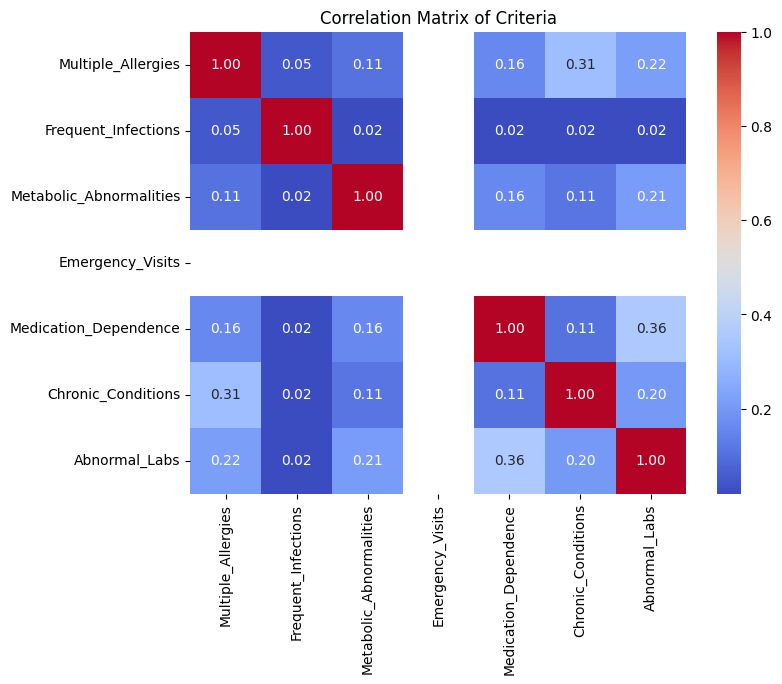

In [11]:
correlation_matrix = criteria_matrix.corr()

# Display correlation matrix
print(correlation_matrix)

# Optionally, visualize using seaborn
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Criteria")
plt.show()


In [11]:
correlation_matrix

,Multiple_Allergies,Frequent_Infections,Metabolic_Abnormalities,Emergency_Visits,Medication_Dependence,Chronic_Conditions,Abnormal_Labs
Multiple_Allergies,1.000000,0.046583,0.106079,0.261836,0.160320,0.312472,0.217748
Frequent_Infections,0.046583,1.000000,0.019590,0.016701,0.019876,0.021265,0.023103
Metabolic_Abnormalities,0.106079,0.019590,1.000000,0.210428,0.160408,0.113613,0.208928
Emergency_Visits,0.261836,0.016701,0.210428,1.000000,0.711400,0.506015,0.391828
Medication_Dependence,0.160320,0.019876,0.160408,0.711400,1.000000,0.107149,0.355900
Chronic_Conditions,0.312472,0.021265,0.113613,0.506015,0.107149,1.000000,0.202577
Abnormal_Labs,0.217748,0.023103,0.208928,0.391828,0.355900,0.202577,1.000000


In [12]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [22]:
df_grouped.to_csv('hypothetical_PIDS_labels_synthea_2.csv')

In [12]:
df_grouped['PIDS_label'].sum()

1757